# Análisis de resultados, errores y confusores

## Entrega P2

En el cuaderno 04 ningún modelo superó a los demás con significancia estadística. El bosque aleatorio tuvo la mayor exactitud balanceada media y la menor variación entre repeticiones, así que es el modelo principal de este análisis; la regresión logística se mantiene como contraste porque sus coeficientes se pueden leer. Este cuaderno intenta entender qué aprendieron y dónde se equivocan:

1. qué clases confunde y qué pares de patologías son separables;
2. si la marcha distingue entre enfermedades o solo separa sanos de enfermos (PI1);
3. qué sujetos falla de forma sistemática y si eso tiene relación con la severidad clínica;
4. qué descriptores usa;
5. cuánto del desempeño podrían explicar la edad, el sexo y la velocidad (PI3);
6. qué tan sensibles son los resultados a las decisiones de preprocesamiento.

Se usan las mismas 50 particiones del cuaderno 04 (misma semilla), de modo que las predicciones son las mismas.

In [1]:
import subprocess
import sys
from pathlib import Path

REPOSITORIO = "https://github.com/jeraldinedione/proyecto-machine-learning.git"


def raiz_del_proyecto(inicio: Path) -> Path:
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "src" / "gait").is_dir():
            return carpeta
    raise FileNotFoundError("No se encontró la raíz del proyecto")


if "google.colab" in sys.modules:
    if not Path("marcha").exists():
        subprocess.run(["git", "clone", "--quiet", REPOSITORIO, "marcha"], check=True)
    RAIZ = Path("marcha").resolve()
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", "-r", str(RAIZ / "requirements.txt")],
        check=True,
    )
else:
    RAIZ = raiz_del_proyecto(Path.cwd())

sys.path.insert(0, str(RAIZ / "src"))
print(RAIZ)

/Users/nllerenas/Chiwawa/proyecto-machine-learning


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from gait import cohort, config, download, evaluation, gaitndd, models, plots

download.fetch(config.GAITNDD)
plots.use_paper_style()
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [3]:
sujetos = gaitndd.read_subject_table()
crudas = gaitndd.read_all_strides()
zancadas = cohort.clean_strides(crudas)
datos = cohort.subject_dataset(zancadas, sujetos)
particiones = evaluation.record_splits(datos, n_splits=5, n_repeats=10)
cortas = plots.short_labels_for(config.GROUP_ORDER)


def media_de(tabla, columna):
    return tabla[f"{columna}_mean"].map("{:.3f}".format) + " ± " + tabla[f"{columna}_sd"].map("{:.3f}".format)

In [4]:
%%time
logistica = evaluation.nested_cv(models.logistic(), datos, particiones, importances=True)
bosque = evaluation.nested_cv(models.random_forest(), datos, particiones, importances=True)
evaluation.summarize([logistica, bosque], config.GROUP_ORDER)[["balanced_accuracy_mean", "macro_f1_mean", "auc_mean"]]

CPU times: user 1min 36s, sys: 1.42 s, total: 1min 38s
Wall time: 2min 15s


,balanced_accuracy_mean,macro_f1_mean,auc_mean
modelo,,,
Regresión logística,0.591,0.583,0.812
Bosque aleatorio,0.605,0.595,0.829


---

## 1. Matriz de confusión y separabilidad por pares

La matriz acumula las 10 repeticiones (630 predicciones, 10 por sujeto) y se normaliza por fila, así que la diagonal es la sensibilidad de cada clase.

La segunda matriz responde otra pregunta: para cada par de grupos, si se toman solo los sujetos de esos dos grupos, ¿el modelo les asigna probabilidades que los ordenen bien? Se calcula el AUC de `p_a / (p_a + p_b)` entre los sujetos de los grupos a y b, promediado entre repeticiones. Un AUC de 0.5 indica que el modelo no distingue ese par.

In [5]:
confusion = evaluation.pooled_confusion(bosque, config.GROUP_ORDER)
proporcion = confusion.div(confusion.sum(axis=1), axis=0)
pares = evaluation.pairwise_auc(bosque, config.GROUP_ORDER)

proporcion.set_axis(cortas, axis=0).set_axis(cortas, axis=1).to_csv(config.TABLES_DIR / "confusion_bosque.csv")
pares.set_axis(cortas, axis=0).set_axis(cortas, axis=1).to_csv(config.TABLES_DIR / "auc_por_pares.csv")
display(confusion.set_axis(cortas, axis=0).set_axis(cortas, axis=1))
pares.set_axis(cortas, axis=0).set_axis(cortas, axis=1)

,Ctrl,EP,EH,ELA
Ctrl,141,4,5,10
EP,15,55,59,21
EH,15,29,125,21
ELA,32,18,13,67


,Ctrl,EP,EH,ELA
Ctrl,NaN,0.955,0.978,0.887
EP,0.955,NaN,0.698,0.804
EH,0.978,0.698,NaN,0.891
ELA,0.887,0.804,0.891,NaN


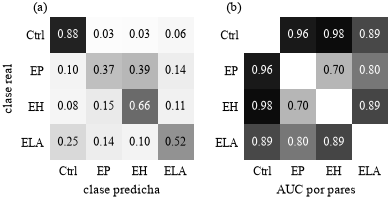

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(plots.COLUMN_WIDTH, 1.75))
plots.annotated_matrix(axes[0], proporcion.set_axis(cortas, axis=0).set_axis(cortas, axis=1))
axes[0].set_xlabel("clase predicha")
axes[0].set_ylabel("clase real")
plots.annotated_matrix(
    axes[1], pares.set_axis(cortas, axis=0).set_axis(cortas, axis=1), vmin=0.5, vmax=1.0, mask_diagonal=True
)
axes[1].set_xlabel("AUC por pares")
plots.panel_label(axes[0], "(a)")
plots.panel_label(axes[1], "(b)")
fig.tight_layout(w_pad=1.2)
plots.save(fig, "confusion_y_pares")

El bosque reconoce bien a los controles (0.88) y confunde sobre todo Parkinson con Huntington: el 39 % de las predicciones de los sujetos con Parkinson van a Huntington, más que las que aciertan (37 %). La matriz de AUC por pares lo confirma. Los controles se separan de cualquier enfermedad (0.89 a 0.98) y el par más difícil es Parkinson–Huntington (0.70). ELA se confunde con control en una cuarta parte de los casos.

---

## 2. ¿Diferencia entre enfermedades o solo separa sanos de enfermos? (PI1)

Se plantean dos tareas por separado, cada una con su propia validación cruzada anidada 5 × 10:

- **Control contra paciente**, con los 63 sujetos. Las particiones se estratifican por los cuatro grupos para que cada partición tenga pacientes de las tres enfermedades.
- **Diagnóstico diferencial**, solo con los 47 pacientes y tres clases. El azar es 0.33.

Si la marcha solo separara sanos de enfermos, la segunda tarea quedaría cerca del azar.

In [7]:
%%time
binario = datos.assign(estado=np.where(datos.group == "control", "control", "paciente"))
particiones_binario = evaluation.record_splits(binario, target="group", n_repeats=10)
pacientes = datos[datos.group != "control"].reset_index(drop=True)
particiones_pacientes = evaluation.record_splits(pacientes, n_repeats=10)

tareas = {
    ("control vs. paciente", "logística"): evaluation.nested_cv(models.logistic(), binario, particiones_binario, target="estado"),
    ("control vs. paciente", "bosque"): evaluation.nested_cv(models.random_forest(), binario, particiones_binario, target="estado"),
    ("diferencial (EP, EH, ELA)", "logística"): evaluation.nested_cv(models.logistic(), pacientes, particiones_pacientes),
    ("diferencial (EP, EH, ELA)", "bosque"): evaluation.nested_cv(models.random_forest(), pacientes, particiones_pacientes),
    ("cuatro clases", "logística"): logistica,
    ("cuatro clases", "bosque"): bosque,
}

CPU times: user 21.4 s, sys: 861 ms, total: 22.2 s
Wall time: 1min 40s


In [8]:
filas = []
for (tarea, modelo), resultado in tareas.items():
    metricas = evaluation.repeat_metrics(resultado)
    filas.append({
        "tarea": tarea,
        "modelo": modelo,
        "azar": 1 / len(resultado.classes),
        "exactitud bal.": f"{metricas.balanced_accuracy.mean():.3f} ± {metricas.balanced_accuracy.std(ddof=1):.3f}",
        "AUC": f"{metricas.auc.mean():.3f} ± {metricas.auc.std(ddof=1):.3f}",
    })
jerarquia = pd.DataFrame(filas).set_index(["tarea", "modelo"])
jerarquia.to_csv(config.TABLES_DIR / "tareas_jerarquicas.csv")
jerarquia

azar exactitud bal.            AUC
tarea                     modelo                                       
control vs. paciente      logística 0.500  0.866 ± 0.023  0.919 ± 0.013
                          bosque    0.500  0.860 ± 0.027  0.940 ± 0.015
diferencial (EP, EH, ELA) logística 0.333  0.619 ± 0.079  0.787 ± 0.041
                          bosque    0.333  0.561 ± 0.062  0.754 ± 0.033
cuatro clases             logística 0.250  0.591 ± 0.041  0.812 ± 0.026
                          bosque    0.250  0.605 ± 0.016  0.829 ± 0.018

In [9]:
binaria = evaluation.repeat_metrics(tareas[("control vs. paciente", "bosque")], ["control", "paciente"])
print(f"sensibilidad para pacientes: {binaria.recall_paciente.mean():.3f}")
print(f"especificidad (controles bien clasificados): {binaria.recall_control.mean():.3f}")
print()
diferencial = evaluation.repeat_metrics(tareas[("diferencial (EP, EH, ELA)", "bosque")], ["park", "hunt", "als"])
print(diferencial[["recall_park", "recall_hunt", "recall_als"]].mean().rename(lambda c: c.replace("recall_", "sensibilidad ")).round(3).to_string())

sensibilidad para pacientes: 0.889
especificidad (controles bien clasificados): 0.831

sensibilidad park   0.393
sensibilidad hunt   0.689
sensibilidad als    0.600


Separar sanos de enfermos es la parte fácil: exactitud balanceada de 0.86 a 0.87 y AUC de 0.92 a 0.94, con sensibilidad de 0.89 para pacientes. Entre las tres enfermedades el desempeño baja a 0.56–0.62, aunque sigue muy por encima del azar (0.33), con AUC de 0.75 a 0.79.

Respuesta a la PI1: la marcha sí lleva información para distinguir entre enfermedades, pero bastante menos que para detectar que hay una. En esta tarea la logística supera al bosque (0.62 contra 0.56), al revés que con cuatro clases. Parkinson sigue siendo la clase que peor se reconoce (0.39).

---

## 3. Sujetos que el modelo falla

Para cada sujeto se calcula en cuántas de las 10 repeticiones fue bien clasificado. Un sujeto que se falla en las 10 no es mala suerte de la partición: su marcha se parece más a la de otro grupo.

In [10]:
aciertos = evaluation.subject_hit_rate(bosque).merge(
    datos[["record", "age", "sex", "speed_ms", "hoehn_yahr", "functional_capacity", "months_since_diagnosis",
           "stride_cv", "dfa_alpha", "double_support_pct_mean"]],
    on="record",
)
print("distribución de la tasa de acierto por sujeto:")
print(aciertos.hit_rate.value_counts(bins=[-0.01, 0.0, 0.5, 0.99, 1.0], sort=False).to_string())
print()
fallados = aciertos[aciertos.hit_rate <= 0.2].sort_values(["y_true", "hit_rate"])
fallados.to_csv(config.TABLES_DIR / "sujetos_fallados.csv", index=False)
fallados.assign(
    y_true=fallados.y_true.map(config.GROUP_SHORT), most_common=fallados.most_common.map(config.GROUP_SHORT)
).rename(columns={"y_true": "real", "most_common": "predicción habitual", "hit_rate": "acierto"})

distribución de la tasa de acierto por sujeto:
(-0.011, 0.0]    14
(0.0, 0.5]       11
(0.5, 0.99]       9
(0.99, 1.0]      29



,record,real,acierto,predicción habitual,age,sex,speed_ms,hoehn_yahr,functional_capacity,months_since_diagnosis,stride_cv,dfa_alpha,double_support_pct_mean
1,als10,ELA,0.000,Ctrl,40,f,1.219,NaN,NaN,14.500,0.030,0.905,34.935
5,als2,ELA,0.000,Ctrl,63,m,1.219,NaN,NaN,14.000,0.018,0.534,31.549
8,als5,ELA,0.000,EP,36,m,NaN,NaN,NaN,5.500,0.094,0.823,31.295
2,als11,ELA,0.100,EP,39,m,1.283,NaN,NaN,7.000,0.051,0.786,33.404
6,als3,ELA,0.100,EH,70,f,0.853,NaN,NaN,13.000,0.066,0.641,33.175
19,control15,Ctrl,0.000,ELA,20,f,1.190,NaN,NaN,NaN,0.050,0.895,27.676
31,hunt11,EH,0.000,EP,33,m,1.260,NaN,11.000,NaN,0.062,0.816,38.483
40,hunt2,EH,0.000,ELA,41,f,1.050,NaN,11.000,NaN,0.084,0.825,31.234
46,hunt8,EH,0.000,Ctrl,53,f,1.260,NaN,9.000,NaN,0.066,0.871,25.918
47,hunt9,EH,0.000,EP,54,f,1.260,NaN,12.000,NaN,0.069,0.877,31.154


14 sujetos se fallan en las 10 repeticiones y 29 se aciertan siempre. Los siete sujetos con Parkinson mal clasificados muestran dos patrones. El más leve (`park2`, Hoehn y Yahr 1.5, DFA de 1.19) se clasifica como control. Cinco de los otros seis van a Huntington y tienen un CV entre 0.064 y 0.103, muy por encima del de los controles (mediana ≈ 0.04): su variabilidad se parece más a la de la corea que a la del Parkinson típico de esta muestra.

,variable,rho,p,n
Control,edad (años),-0.063,0.817,16
Parkinson,Hoehn y Yahr,-0.078,0.783,15
Huntington,capacidad funcional total,-0.761,0.000,19
ELA,meses desde el diagnóstico,0.232,0.446,13


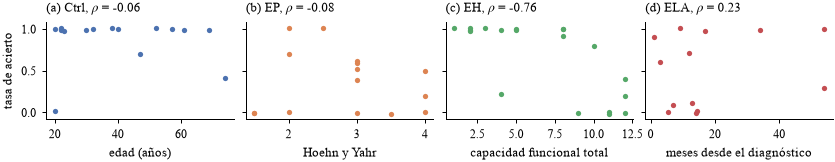

In [11]:
paneles = [
    ("control", "age", "edad (años)"),
    ("park", "hoehn_yahr", "Hoehn y Yahr"),
    ("hunt", "functional_capacity", "capacidad funcional total"),
    ("als", "months_since_diagnosis", "meses desde el diagnóstico"),
]
fig, axes = plt.subplots(1, 4, figsize=(plots.PAGE_WIDTH, 1.55), sharey=True)
correlaciones = {}
for ax, (grupo, columna, etiqueta), letra in zip(axes, paneles, "abcd"):
    parte = aciertos[aciertos.y_true == grupo]
    rho, p = stats.spearmanr(parte[columna], parte.hit_rate)
    correlaciones[config.GROUP_LABELS[grupo]] = {"variable": etiqueta, "rho": rho, "p": p, "n": len(parte)}
    desplazamiento = np.random.default_rng(1).uniform(-0.02, 0.02, len(parte))
    ax.scatter(parte[columna], parte.hit_rate + desplazamiento, s=10, color=config.GROUP_COLORS[grupo], lw=0)
    ax.set_xlabel(etiqueta)
    ax.set_title(rf"({letra}) {config.GROUP_SHORT[grupo]}, $\rho$ = {rho:.2f}", loc="left")
axes[0].set_ylabel("tasa de acierto")
axes[0].set_ylim(-0.08, 1.08)
fig.tight_layout(w_pad=0.6)
plots.save(fig, "errores_severidad")
pd.DataFrame(correlaciones).T

La única relación clara aparece en Huntington: ρ = −0.76 entre la capacidad funcional y la tasa de acierto. Los pacientes con mayor capacidad funcional (enfermedad más leve, 9 a 12 puntos) se fallan casi siempre, y los más deteriorados se aciertan siempre. En Parkinson no hay relación con Hoehn y Yahr (ρ = −0.08), porque se fallan tanto casos leves como avanzados, por los dos motivos de la tabla anterior. En ELA tampoco con los meses desde el diagnóstico, que de todos modos es una medida pobre de severidad.

Cada punto es un sujeto. En Huntington una capacidad funcional menor indica mayor deterioro; en Parkinson, un Hoehn y Yahr mayor. Estas escalas no entran al modelo (son fuga de la etiqueta), pero sirven para ver si los errores se concentran en los casos leves.

---

## 4. Qué descriptores usa el modelo

**Importancia por permutación.** En cada una de las 50 particiones, sobre los sujetos de prueba, se baraja una variable a la vez (20 veces) y se mide cuánto cae la exactitud balanceada. Se calcula fuera de muestra, así que mide lo que el modelo usa para generalizar. Con variables correlacionadas la importancia se reparte: si dos descriptores llevan la misma información, barajar uno no hace mucho daño porque queda el otro.

In [12]:
def resumen_importancia(resultado):
    tabla = resultado.importances
    return pd.DataFrame({"media": tabla.mean(), "error estándar": tabla.std(ddof=1) / np.sqrt(len(tabla))})


importancias = pd.concat(
    {"logística": resumen_importancia(logistica), "bosque": resumen_importancia(bosque)}, axis=1
).sort_values(("bosque", "media"), ascending=False)
importancias.to_csv(config.TABLES_DIR / "importancia_permutacion.csv")
importancias

logística                bosque               
                            media error estándar  media error estándar
stride_mean                 0.108          0.013  0.073          0.012
swing_pct_cv                0.018          0.007  0.055          0.008
stride_iqr                  0.026          0.007  0.028          0.008
double_support_pct_mean     0.094          0.012  0.026          0.008
dfa_alpha                   0.016          0.010  0.012          0.007
sample_entropy              0.013          0.008  0.010          0.006
asymmetry_swing             0.001          0.006  0.000          0.005
autocorr_lag1              -0.012          0.006 -0.001          0.006
stride_cv                   0.037          0.009 -0.002          0.007
stride_diff_cv              0.045          0.008 -0.005          0.007
asymmetry_stride            0.008          0.005 -0.006          0.003
double_support_pct_cv       0.036          0.010 -0.012          0.008

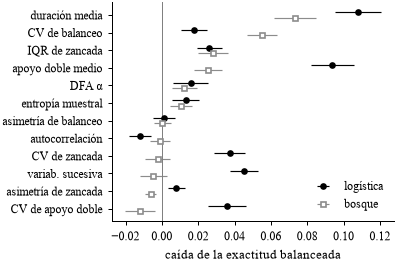

In [13]:
orden = importancias.index[::-1]
posiciones = np.arange(len(orden))
fig, ax = plt.subplots(figsize=(plots.COLUMN_WIDTH, 2.4))
for desplazamiento, modelo, marcador, color in [(0.15, "logística", "o", "black"), (-0.15, "bosque", "s", "0.55")]:
    ax.errorbar(
        importancias.loc[orden, (modelo, "media")], posiciones + desplazamiento,
        xerr=importancias.loc[orden, (modelo, "error estándar")],
        fmt=marcador, ms=3, color=color, mfc=color if modelo == "logística" else "white",
        capsize=0, lw=0.7, label=modelo,
    )
ax.axvline(0, color="0.5", lw=0.6)
ax.set_yticks(posiciones, [config.FEATURE_LABELS[f] for f in orden])
ax.set_xlabel("caída de la exactitud balanceada")
ax.legend(loc="lower right")
fig.tight_layout()
plots.save(fig, "importancia_permutacion")

Los dos modelos coinciden en la variable principal: la duración media de la zancada (0.11 en la logística, 0.07 en el bosque). Después, la logística usa el apoyo doble medio (0.09) y las medidas de variabilidad; el bosque, el CV del balanceo (0.06) y el IQR. DFA y la entropía muestral aportan poco por separado (0.01 a 0.02).

Los modelos difieren en las medidas de variabilidad. Para la logística, el CV, la variabilidad sucesiva y el CV del apoyo doble valen cerca de 0.04 cada una; para el bosque, barajar cualquiera de ellas no cambia nada. Como están correlacionadas con r > 0.75, el bosque puede usar una en lugar de otra, y la importancia por permutación de cada una sola queda en cero. Este es el sesgo conocido de la importancia por permutación con variables correlacionadas.

Que la variable más importante sea la duración media, que depende de la velocidad, anticipa lo que muestra la sección 5.

**Coeficientes de la regresión logística.** Se reentrena el modelo con los 63 sujetos y la combinación de hiperparámetros elegida con más frecuencia en el cuaderno 04. Las variables están estandarizadas, así que un coeficiente de 1 indica que un aumento de una desviación estándar multiplica por e las chances de esa clase frente a las demás. No es una estimación fuera de muestra: sirve para leer la dirección de los efectos.

In [14]:
fijos = evaluation.most_frequent_params(logistica)
final = models.logistic().with_params(**fijos).estimator.fit(datos[config.GAIT_FEATURES], datos.group)
coeficientes = pd.DataFrame(
    final.named_steps["model"].coef_.T,
    index=[config.FEATURE_LABELS[f] for f in config.GAIT_FEATURES],
    columns=final.named_steps["model"].classes_,
)[config.GROUP_ORDER].rename(columns=config.GROUP_SHORT)
coeficientes.to_csv(config.TABLES_DIR / "coeficientes_logistica.csv")
print(fijos)
coeficientes.round(2)

{'model__C': 0.03, 'model__l1_ratio': 0.0}


,Ctrl,EP,EH,ELA
duración media,-0.110,-0.110,-0.080,0.300
CV de zancada,-0.150,0.030,0.140,-0.030
IQR de zancada,-0.110,-0.040,0.110,0.040
variab. sucesiva,-0.120,0.010,0.160,-0.050
asimetría de zancada,-0.030,0.040,0.010,-0.020
autocorrelación,0.100,-0.050,-0.110,0.060
DFA α,0.090,0.040,-0.170,0.050
entropía muestral,-0.050,-0.090,0.100,0.040
CV de balanceo,-0.150,0.080,0.100,-0.030
apoyo doble medio,-0.170,0.120,-0.090,0.150


Los signos son coherentes con la clínica: ELA se asocia a zancadas largas (+0.30) y más apoyo doble; Huntington, a más variabilidad y menor DFA (−0.17); control, a menos variabilidad y menos apoyo doble. La regularización elegida (C = 0.03, L2) es fuerte, y por eso los coeficientes son pequeños.

---

## 5. Confusores: edad, sexo y velocidad (PI3)

Si la edad y el sexo bastaran para clasificar casi tan bien como la marcha, el resultado del cuaderno 04 sería sospechoso. Se repite la validación anidada con los dos modelos y cinco conjuntos de variables.

In [15]:
%%time
conjuntos = {
    "marcha": config.GAIT_FEATURES,
    "edad y sexo": config.DEMOGRAPHIC_FEATURES,
    "velocidad": config.SPEED_FEATURES,
    "marcha + edad y sexo": config.GAIT_FEATURES + config.DEMOGRAPHIC_FEATURES,
    "marcha + edad, sexo y velocidad": config.GAIT_FEATURES + config.DEMOGRAPHIC_FEATURES + config.SPEED_FEATURES,
}
por_conjunto = [
    evaluation.nested_cv(constructor(variables).labelled(f"{nombre} ({etiqueta})"), datos, particiones)
    for nombre, variables in conjuntos.items()
    for constructor, etiqueta in [(models.logistic, "logística"), (models.random_forest, "bosque")]
]

CPU times: user 1min, sys: 2.26 s, total: 1min 2s
Wall time: 4min 27s


In [16]:
resumen_conjuntos = evaluation.summarize(por_conjunto, config.GROUP_ORDER)
resumen_conjuntos.to_csv(config.TABLES_DIR / "conjuntos_confusores.csv")
pd.DataFrame({
    "exactitud bal.": media_de(resumen_conjuntos, "balanced_accuracy"),
    "AUC": media_de(resumen_conjuntos, "auc"),
    **{f"sens. {config.GROUP_SHORT[g]}": resumen_conjuntos[f"recall_{g}_mean"].round(2) for g in config.GROUP_ORDER},
})

,exactitud bal.,AUC,sens. Ctrl,sens. EP,sens. EH,sens. ELA
modelo,,,,,,
marcha (logística),0.591 ± 0.041,0.812 ± 0.026,0.820,0.370,0.660,0.520
marcha (bosque),0.605 ± 0.016,0.829 ± 0.018,0.880,0.370,0.660,0.520
edad y sexo (logística),0.462 ± 0.041,0.726 ± 0.019,0.690,0.610,0.110,0.440
edad y sexo (bosque),0.439 ± 0.038,0.712 ± 0.023,0.440,0.470,0.390,0.450
velocidad (logística),0.400 ± 0.026,0.620 ± 0.019,0.820,0.630,0.100,0.050
velocidad (bosque),0.524 ± 0.048,0.745 ± 0.023,0.670,0.460,0.310,0.660
marcha + edad y sexo (logística),0.665 ± 0.044,0.867 ± 0.021,0.850,0.490,0.660,0.660
marcha + edad y sexo (bosque),0.659 ± 0.046,0.862 ± 0.018,0.880,0.510,0.710,0.540
"marcha + edad, sexo y velocidad (logística)",0.670 ± 0.039,0.863 ± 0.030,0.840,0.560,0.620,0.650


In [17]:
puntajes = {r.spec.label: evaluation.fold_scores(r) for r in por_conjunto}
n_prueba = len(datos) / 5
for modelo in ["logística", "bosque"]:
    for a, b in [("marcha + edad y sexo", "marcha"), ("marcha", "edad y sexo")]:
        x, y = puntajes[f"{a} ({modelo})"], puntajes[f"{b} ({modelo})"]
        t, p = evaluation.corrected_ttest(x, y, len(datos) - n_prueba, n_prueba)
        print(f"{modelo}: {a} contra {b}: diferencia {(x - y).mean():+.3f}, p = {p:.3f}")

logística: marcha + edad y sexo contra marcha: diferencia +0.074, p = 0.245
logística: marcha contra edad y sexo: diferencia +0.131, p = 0.146
bosque: marcha + edad y sexo contra marcha: diferencia +0.051, p = 0.315
bosque: marcha contra edad y sexo: diferencia +0.169, p = 0.059


Edad y sexo solos clasifican con 0.44–0.46, muy por encima del azar (0.25), y la velocidad sola con 0.40–0.52. La marcha llega a 0.59–0.61. Agregar edad y sexo a la marcha sube a 0.66, y sumar la velocidad, a 0.67–0.68. Ninguna de estas diferencias es significativa con la prueba corregida (p entre 0.06 y 0.32).

Se pueden sacar dos conclusiones. La demografía por sí sola ya separa bastante los grupos de esta cohorte, que es justamente el problema señalado en P1. Y la marcha y la demografía aportan información en parte distinta, porque juntas rinden más que cada una por separado.

Dentro de `gaitndd` esta comparación tiene un límite: la edad y la clase están tan asociadas que un descriptor de marcha correlacionado con la edad puede estar midiendo edad. La prueba más fuerte está en el cuaderno 06, con la cohorte externa donde la edad casi no difiere entre grupos.

---

## 6. Sensibilidad a las decisiones de preprocesamiento

Se repite la evaluación del bosque aleatorio cambiando una decisión a la vez:

- **Filtrado**: sin filtro, fisiológico (el usado) y fisiológico más el filtro de dispersión de ± 4 MAD.
- **Pie**: descriptores calculados con la zancada izquierda (el usado), la derecha o el promedio de ambas.
- **Largo de ventana** en el enfoque por ventanas: 20, 30 y 60 zancadas. Por costo, se usan las 5 primeras repeticiones.

In [18]:
%%time
variantes = {}
for modo, nombre in [("none", "sin filtro"), ("physiological", "fisiológico"), ("strict", "fisiológico + MAD")]:
    tabla = cohort.subject_dataset(cohort.clean_strides(crudas, modo), sujetos)
    variantes[("filtrado", nombre)] = evaluation.nested_cv(models.random_forest(), tabla, particiones)
for lado, nombre in [("left", "izquierdo"), ("right", "derecho"), ("both", "promedio")]:
    tabla = cohort.subject_dataset(zancadas, sujetos, side=lado)
    variantes[("pie", nombre)] = evaluation.nested_cv(models.random_forest(), tabla, particiones)

variables_ventana = [f for f in config.GAIT_FEATURES if f != "sample_entropy"]
for largo in [20, 30, 60]:
    tabla = cohort.window_dataset(zancadas, sujetos, window_strides=largo)
    variantes[("ventana (bosque)", f"{largo} zancadas")] = evaluation.nested_cv(
        models.random_forest(variables_ventana), tabla, particiones[:25]
    )

CPU times: user 1min 19s, sys: 2.05 s, total: 1min 21s
Wall time: 6min 51s


In [19]:
filas = []
for (decision, opcion), resultado in variantes.items():
    metricas = evaluation.repeat_metrics(resultado)
    filas.append({
        "decisión": decision,
        "opción": opcion,
        "exactitud bal.": metricas.balanced_accuracy.mean(),
        "DE": metricas.balanced_accuracy.std(ddof=1),
        "AUC": metricas.auc.mean(),
    })
sensibilidad = pd.DataFrame(filas).set_index(["decisión", "opción"])
sensibilidad.to_csv(config.TABLES_DIR / "sensibilidad.csv")
sensibilidad

exactitud bal.    DE   AUC
decisión         opción                                       
filtrado         sin filtro                  0.611 0.048 0.833
                 fisiológico                 0.605 0.016 0.829
                 fisiológico + MAD           0.638 0.025 0.835
pie              izquierdo                   0.605 0.016 0.829
                 derecho                     0.598 0.026 0.828
                 promedio                    0.623 0.022 0.839
ventana (bosque) 20 zancadas                 0.645 0.033 0.848
                 30 zancadas                 0.647 0.018 0.853
                 60 zancadas                 0.603 0.023 0.818

Sin filtro, el bosque rinde igual (0.611 contra 0.605), y con el filtro MAD, algo más (0.638). Eso no quiere decir que el filtrado sobre. Sin filtro, los descriptores de ELA y Parkinson incluyen pausas y fallos del sensor, que son más frecuentes en pacientes y por eso también discriminan: un modelo entrenado así estaría usando los errores de detección como síntoma.

El promedio de ambos pies da 0.623 y el pie derecho, 0.598, así que la elección del lado no cambia las conclusiones. En el enfoque por ventanas, 20 y 30 zancadas rinden igual (0.645 y 0.647) y 60 baja a 0.603, posiblemente porque cada sujeto aporta la mitad de ventanas. Todas las variaciones quedan dentro de ±0.04 del valor principal, del mismo orden que la desviación entre repeticiones.